# Task-1

In [ ]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import roc_curve, roc_auc_score


In [2]:
#Load the Titanic dataset
df = pd.read_csv("titanic.csv")

df.head()

,Survived,Pclass,Sex,Age,SibSp,Parch,Fare
0,1,2,female,17.8,0,0,23.94
1,0,3,male,18.5,1,0,29.07
2,0,3,male,26.6,1,0,17.63
3,0,3,male,34.7,0,2,13.72
4,1,1,male,42.0,0,0,128.90


In [3]:
#Encode the Sex column
df["Sex"] = (df["Sex"] == "female").astype(int)

df[["Sex"]].head()

,Sex
0,1
1,0
2,0
3,0
4,0


In [4]:
#Separate features and target
X = df.drop(columns=["Survived"])
y = df["Survived"].values

In [5]:
#Split the dataset
X_train, X_test, y_train, y_test = train_test_split(X,y,test_size=0.2,random_state=42,stratify=y)

In [6]:
#Standardize the features
scaler = StandardScaler().fit(X_train)

X_tr = scaler.transform(X_train)
X_te = scaler.transform(X_test)

In [7]:
print("Original dataset shape:", df.shape)

print("X_train shape:", X_train.shape)
print("X_test shape:", X_test.shape)

print("y_train shape:", y_train.shape)
print("y_test shape:", y_test.shape)

print("Training survival proportion:", y_train.mean())
print("Testing survival proportion:", y_test.mean())

Original dataset shape: (1000, 7)
X_train shape: (800, 6)
X_test shape: (200, 6)
y_train shape: (800,)
y_test shape: (200,)
Training survival proportion: 0.44
Testing survival proportion: 0.44


# TASK-2

In [8]:
def sigmoid(z):
    return 1 / (1 + np.exp(-z))

In [9]:
print("Sigmoid of 0:", sigmoid(0))
print("Sigmoid of 5:", sigmoid(5))
print("Sigmoid of -5:", sigmoid(-5))

Sigmoid of 0: 0.5
Sigmoid of 5: 0.9933071490757153
Sigmoid of -5: 0.0066928509242848554


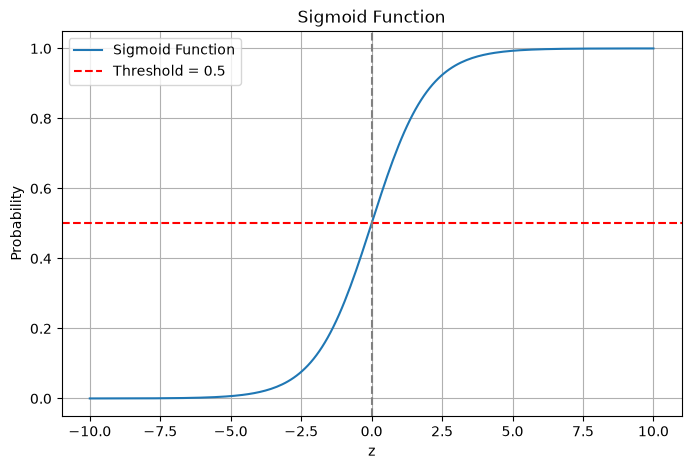

In [10]:
#Plot the sigmoid curve
# Generate values from -10 to +10
z = np.linspace(-10, 10, 200)

# Calculate sigmoid probabilities
y_sigmoid = sigmoid(z)

# Plot the sigmoid curve
plt.figure(figsize=(8, 5))
plt.plot(z, y_sigmoid, label="Sigmoid Function")

# Highlight the 0.5 decision threshold
plt.axhline(y=0.5, color="red", linestyle="--", label="Threshold = 0.5")
plt.axvline(x=0, color="gray", linestyle="--")

plt.title("Sigmoid Function")
plt.xlabel("z")
plt.ylabel("Probability")
plt.legend()
plt.grid(True)
plt.show()

In [11]:
y_true = 1
p = 0.9

loss = -(y_true * np.log(p) + (1 - y_true) * np.log(1 - p))

print("Log-Loss:", loss)

Log-Loss: 0.10536051565782628


In [12]:
y_true = 1
p = 0.05

loss = -(y_true * np.log(p) + (1 - y_true) * np.log(1 - p))

print("Log-Loss:", loss)

Log-Loss: 2.995732273553991


# TASK-3

In [13]:
class LogisticRegressionScratch:

    def __init__(self, learning_rate=0.01, iterations=2000):
        self.learning_rate = learning_rate
        self.iterations = iterations
        self.w = None
        self.b = 0
        self.loss_history = []

    # Sigmoid function
    def sigmoid(self, z):
        return 1 / (1 + np.exp(-np.clip(z, -500, 500)))

    # Binary Cross-Entropy Loss
    def compute_loss(self, y, p):
        epsilon = 1e-15
        p = np.clip(p, epsilon, 1 - epsilon)

        loss = -np.mean(
            y * np.log(p) + (1 - y) * np.log(1 - p)
        )

        return loss

    # Train the model using Gradient Descent
    def fit(self, X, y):

        m, n = X.shape

        # Initialize weights and bias
        self.w = np.zeros(n)
        self.b = 0

        # Gradient Descent loop
        for i in range(self.iterations):

            # Calculate predictions
            z = np.dot(X, self.w) + self.b
            p = self.sigmoid(z)

            # Calculate loss
            loss = self.compute_loss(y, p)
            self.loss_history.append(loss)

            # Calculate gradients
            dw = np.dot(X.T, (p - y)) / m
            db = np.sum(p - y) / m

            # Update weights and bias
            self.w = self.w - self.learning_rate * dw
            self.b = self.b - self.learning_rate * db

        return self

    # Predict probabilities
    def predict_proba(self, X):
        z = np.dot(X, self.w) + self.b
        return self.sigmoid(z)

    # Predict classes
    def predict(self, X, threshold=0.5):
        probabilities = self.predict_proba(X)
        return (probabilities >= threshold).astype(int)

In [14]:
scratch = LogisticRegressionScratch(
    learning_rate=0.01,
    iterations=2000
)

scratch.fit(X_tr, y_train)

In [15]:
print("Learned weights:")
print(scratch.w)

print("\nLearned bias:")
print(scratch.b)

Learned weights:
[-0.58877302  1.10287791 -0.05761762 -0.19314838 -0.03281642  0.19949241]

Learned bias:
-0.2641172086211555


In [16]:
weights_df = pd.DataFrame({
    "Feature": X_train.columns,
    "Weight": scratch.w
})

print(weights_df)

  Feature    Weight
0  Pclass -0.588773
1     Sex  1.102878
2     Age -0.057618
3   SibSp -0.193148
4   Parch -0.032816
5    Fare  0.199492


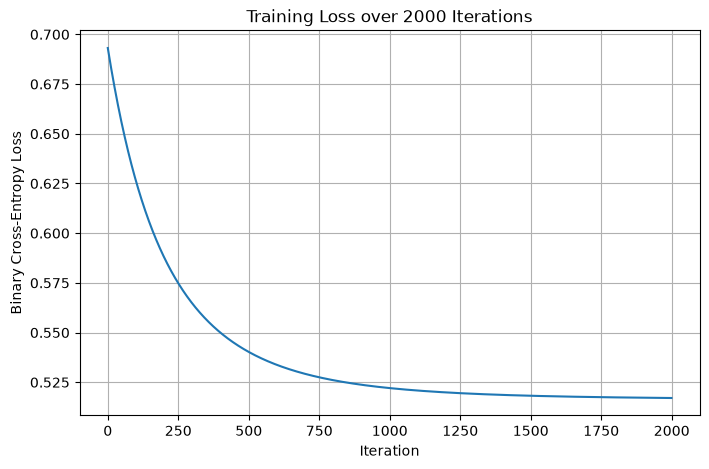

In [17]:
plt.figure(figsize=(8, 5))

plt.plot(scratch.loss_history)

plt.title("Training Loss over 2000 Iterations")
plt.xlabel("Iteration")
plt.ylabel("Binary Cross-Entropy Loss")

plt.grid(True)
plt.show()

In [18]:
print("Initial Loss:", scratch.loss_history[0])
print("Final Loss:", scratch.loss_history[-1])

Initial Loss: 0.6931471805599452
Final Loss: 0.5170928346763154


# TASK_3

In [19]:
#import a libarary
from sklearn.linear_model import LogisticRegression

In [20]:
#Train the Scikit-Learn model
sk_model = LogisticRegression(penalty=None,solver="lbfgs",max_iter=1000)

sk_model.fit(X_tr, y_train)

c:\Users\dell\anaconda3\Lib\site-packages\sklearn\linear_model\_logistic.py:1403: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(


,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",None
,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",1000
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneUsed when ``solver`` == 'sag', 'saga' or 'liblinear' to shuffle thedata. See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.T

In [21]:
#Compare the weights and bias
parity_df = pd.DataFrame({
    "Feature": ["Bias"] + list(X_train.columns),
    "Scratch": [scratch.b] + list(scratch.w),
    "Sklearn": [sk_model.intercept_[0]] + list(sk_model.coef_[0])
})

parity_df

,Feature,Scratch,Sklearn
0,Bias,-0.264117,-0.278052
1,Pclass,-0.588773,-0.696723
2,Sex,1.102878,1.166253
3,Age,-0.057618,-0.061025
4,SibSp,-0.193148,-0.212460
5,Parch,-0.032816,-0.043259
6,Fare,0.199492,0.121748


In [22]:
#Calculate the difference between weights
weight_diff = np.abs(scratch.w - sk_model.coef_[0])
bias_diff = abs(scratch.b - sk_model.intercept_[0])

print("Maximum weight difference:", weight_diff.max())
print("Bias difference:", bias_diff)

print(
    "Weights match within 1e-3:",
    np.allclose(scratch.w, sk_model.coef_[0], atol=1e-3)
)

print(
    "Bias matches within 1e-3:",
    np.isclose(scratch.b, sk_model.intercept_[0], atol=1e-3)
)

Maximum weight difference: 0.10794981382074031
Bias difference: 0.01393443626038915
Weights match within 1e-3: False
Bias matches within 1e-3: False


In [23]:
#Compare test-set predictions
scratch_pred = scratch.predict(X_te)
sklearn_pred = sk_model.predict(X_te)

print("Predictions match:",
      np.array_equal(scratch_pred, sklearn_pred))

print("Scratch predictions:", scratch_pred[:20])
print("Sklearn predictions:", sklearn_pred[:20])

Predictions match: False
Scratch predictions: [1 0 1 0 1 0 0 1 1 1 1 1 0 0 1 0 0 0 0 1]
Sklearn predictions: [1 0 1 0 1 0 0 1 1 1 1 1 0 0 1 0 0 0 0 1]


In [24]:
#Compare predicted probabilities
scratch_probs = scratch.predict_proba(X_te)
sklearn_probs = sk_model.predict_proba(X_te)[:, 1]

print(
    "Maximum probability difference:",
    np.max(np.abs(scratch_probs - sklearn_probs))
)

Maximum probability difference: 0.08333834259183115


# Task-4

In [ ]:
from sklearn.metrics import confusion_matrix,accuracy_score, precision_score, recall_score, f1_score

In [26]:
#predicat the test data
y_pred = sk_model.predict(X_te)

In [27]:
#calculate a confusion matrix
cm = confusion_matrix(y_test, y_pred)

print(cm)

[[86 26]
 [21 67]]


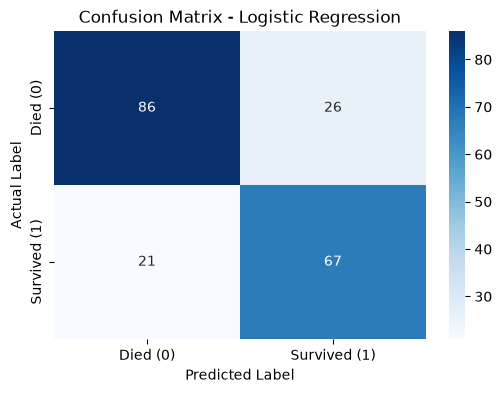

In [28]:
plt.figure(figsize=(6, 4))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Died (0)", "Survived (1)"],
    yticklabels=["Died (0)", "Survived (1)"]
)

plt.title("Confusion Matrix - Logistic Regression")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")

plt.show()

In [29]:
#calculate a clssification matrix
accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred, zero_division=0)
recall = recall_score(y_test, y_pred, zero_division=0)
f1 = f1_score(y_test, y_pred, zero_division=0)

print("Accuracy:", accuracy)
print("Precision:", precision)
print("Recall:", recall)
print("F1-Score:", f1)

Accuracy: 0.765
Precision: 0.7204301075268817
Recall: 0.7613636363636364
F1-Score: 0.7403314917127072


In [30]:
#display all matrix in a dataframe
metrics_df = pd.DataFrame({
    "Metric": ["Accuracy", "Precision", "Recall", "F1-Score"],
    "Score": [accuracy, precision, recall, f1]
})

metrics_df

,Metric,Score
0,Accuracy,0.765000
1,Precision,0.720430
2,Recall,0.761364
3,F1-Score,0.740331


# Task 06

In [31]:
probs = sk_model.predict_proba(X_te)[:, 1]

print("First 10 predicted probabilities:")
print(probs[:10])

First 10 predicted probabilities:
[0.91276928 0.29253588 0.94121233 0.12679747 0.80238844 0.30848975
 0.17331034 0.95489006 0.70668339 0.51299076]


In [32]:
thresholds = [0.2, 0.5, 0.8]

results = []

for threshold in thresholds:

    # Convert probabilities into class predictions
    y_pred_threshold = (probs >= threshold).astype(int)

    # Calculate Precision and Recall
    precision = precision_score(
        y_test, y_pred_threshold, zero_division=0
    )

    recall = recall_score(
        y_test, y_pred_threshold, zero_division=0
    )

    results.append({
        "Threshold": threshold,
        "Precision": precision,
        "Recall": recall
    })

threshold_df = pd.DataFrame(results)

threshold_df

,Threshold,Precision,Recall
0,0.2,0.618321,0.920455
1,0.5,0.720430,0.761364
2,0.8,1.000000,0.375000


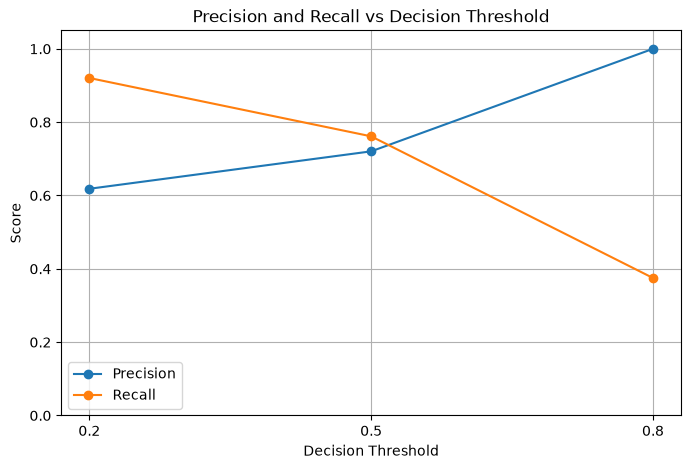

In [33]:
plt.figure(figsize=(8, 5))

plt.plot(
    threshold_df["Threshold"],
    threshold_df["Precision"],
    marker="o",
    label="Precision"
)

plt.plot(
    threshold_df["Threshold"],
    threshold_df["Recall"],
    marker="o",
    label="Recall"
)

plt.title("Precision and Recall vs Decision Threshold")
plt.xlabel("Decision Threshold")
plt.ylabel("Score")
plt.xticks(thresholds)
plt.ylim(0, 1.05)
plt.legend()
plt.grid(True)

plt.show()

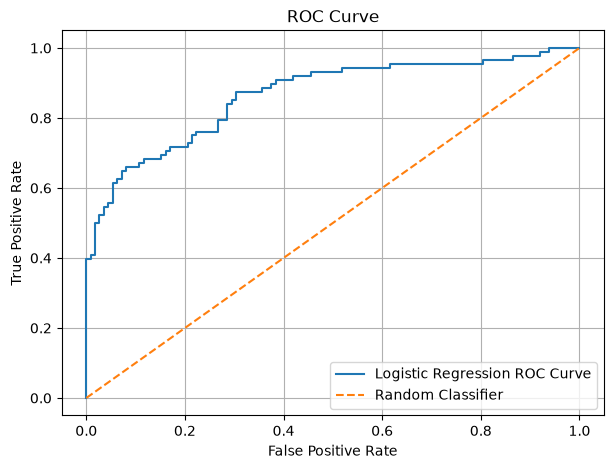

In [34]:
fpr, tpr, roc_thresholds = roc_curve(y_test, probs)

plt.figure(figsize=(7, 5))

plt.plot(
    fpr,
    tpr,
    label="Logistic Regression ROC Curve"
)

# Random classifier reference line
plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Random Classifier"
)

plt.title("ROC Curve")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.legend()
plt.grid(True)

plt.show()

In [35]:
roc_auc = roc_auc_score(y_test, probs)

print("ROC-AUC Score:", roc_auc)

ROC-AUC Score: 0.8643465909090909


# Task-7

In [36]:
# Get feature names and model coefficients
feature_names = X_train.columns
weights = sk_model.coef_[0]

# Calculate odds ratios
odds_ratios = np.exp(weights)

# Create a DataFrame
odds_df = pd.DataFrame({
    "Feature": feature_names,
    "Weight": weights,
    "Odds Ratio": odds_ratios
})

odds_df

,Feature,Weight,Odds Ratio
0,Pclass,-0.696723,0.498215
1,Sex,1.166253,3.209942
2,Age,-0.061025,0.940799
3,SibSp,-0.212460,0.808593
4,Parch,-0.043259,0.957663
5,Fare,0.121748,1.129470


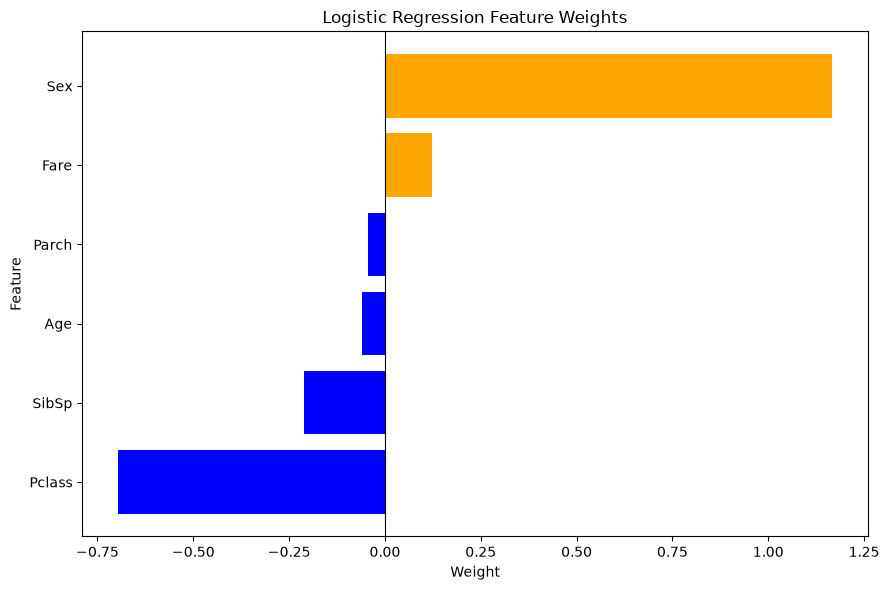

In [37]:
# Sort features by their weights
weights_df = pd.DataFrame({
    "Feature": feature_names,
    "Weight": weights
}).sort_values("Weight")

# Assign colors based on positive or negative weights
colors = [
    "orange" if weight > 0 else "blue"
    for weight in weights_df["Weight"]
]

# Create horizontal bar chart
plt.figure(figsize=(9, 6))

plt.barh(
    weights_df["Feature"],
    weights_df["Weight"],
    color=colors
)

plt.axvline(x=0, color="black", linewidth=0.8)

plt.title("Logistic Regression Feature Weights")
plt.xlabel("Weight")
plt.ylabel("Feature")

plt.tight_layout()
plt.show()

In [38]:
odds_df = odds_df.sort_values(
    "Weight",
    key=abs,
    ascending=False
)

odds_df

,Feature,Weight,Odds Ratio
1,Sex,1.166253,3.209942
0,Pclass,-0.696723,0.498215
3,SibSp,-0.212460,0.808593
5,Fare,0.121748,1.129470
2,Age,-0.061025,0.940799
4,Parch,-0.043259,0.957663


The Logistic Regression model identifies demographic and passenger-related characteristics associated with Titanic survival. The Sex feature compares female passengers with male passengers, with a positive coefficient indicating higher predicted odds of survival for females. Other features, such as passenger class, age, and family-related variables, may also be associated with survival, depending on their learned coefficients. These relationships describe patterns in the dataset and do not prove that a particular characteristic caused a passenger to survive.

In [39]:
positive_features = odds_df[odds_df["Weight"] > 0]
negative_features = odds_df[odds_df["Weight"] < 0]

print("Features positively associated with survival:")
print(positive_features[["Feature", "Weight", "Odds Ratio"]])

print("\nFeatures negatively associated with survival:")
print(negative_features[["Feature", "Weight", "Odds Ratio"]])

Features positively associated with survival:
  Feature    Weight  Odds Ratio
1     Sex  1.166253    3.209942
5    Fare  0.121748    1.129470

Features negatively associated with survival:
  Feature    Weight  Odds Ratio
0  Pclass -0.696723    0.498215
3   SibSp -0.212460    0.808593
2     Age -0.061025    0.940799
4   Parch -0.043259    0.957663
